<a href="https://colab.research.google.com/github/HSOPedro/C11B/blob/main/Cap_6_EXERCICIOS_(Partes_3_e_4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- 1. Utilizando o dataset Iris do Seaborn, para os dados apenas da espécie ‘setosa’, avalie a correlação entre suas variáveis numéricas, apresentando
os valores das correlações e permitindo identificar quais variáveis estão
mais correlacionadas;
- 2. Utilizando do dataset titanic, proponha um gráfico que apresente a
distribuição das idades dos passageiros, diferenciando os dados por sexo e
incluindo uma curva de densidade (KDE);
- 3. Utilizando novamente o dataset titanic, analise a distribuição das idades
dos passageiros em função da classe, segmentando os dados por sexo, de
modo a construir uma visualização que permita comparar a tendência
central, a dispersão e possíveis valores extremos entre os grupos;
- 4. Utilizando do dataset mpg, analise a relação entre a potência dos
veículos (horsepower) e o consumo de combustível (mpg), construindo uma
visualização que permita identificar a tendência entre essas variáveis e
interpretar seu comportamento
;


Correlação entre as variáveis:
              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000     0.742547      0.267176     0.278098
sepal_width       0.742547     1.000000      0.177700     0.232752
petal_length      0.267176     0.177700      1.000000     0.331630
petal_width       0.278098     0.232752      0.331630     1.000000


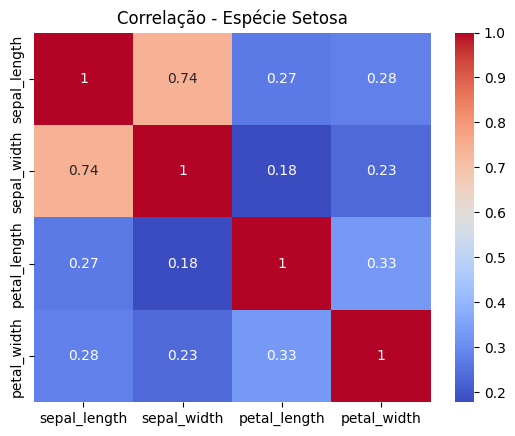

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

iris = sns.load_dataset('iris')

setosa = iris.loc[iris['species'] == 'setosa']

correlacao = setosa.select_dtypes(include='number').corr()

print("Correlação entre as variáveis:")
print(correlacao)

sns.heatmap(correlacao, annot=True, cmap='coolwarm')
plt.title('Correlação - Espécie Setosa')
plt.show()

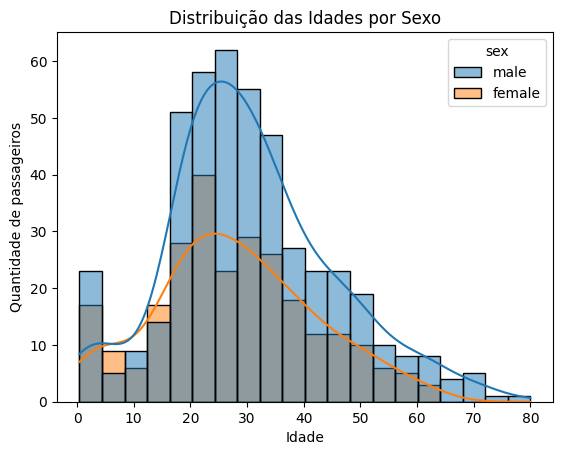

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

titanic = sns.load_dataset('titanic')

sns.histplot(data=titanic, x='age', hue='sex', kde=True)

plt.title('Distribuição das Idades por Sexo')
plt.xlabel('Idade')
plt.ylabel('Quantidade de passageiros')
plt.show()

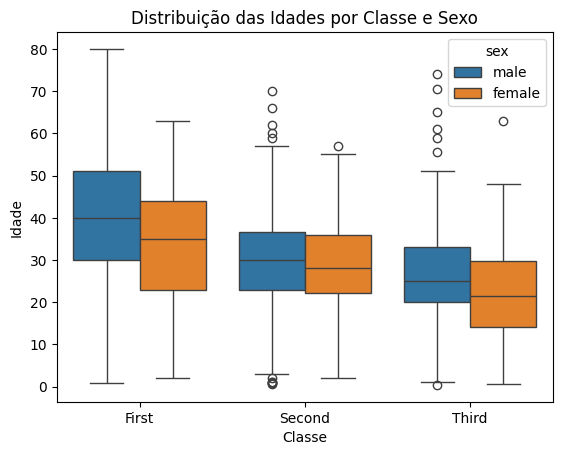

In [11]:
sns.boxplot(
    data=titanic,
    x='class',
    y='age',
    hue='sex'
)

plt.title('Distribuição das Idades por Classe e Sexo')
plt.xlabel('Classe')
plt.ylabel('Idade')
plt.show()

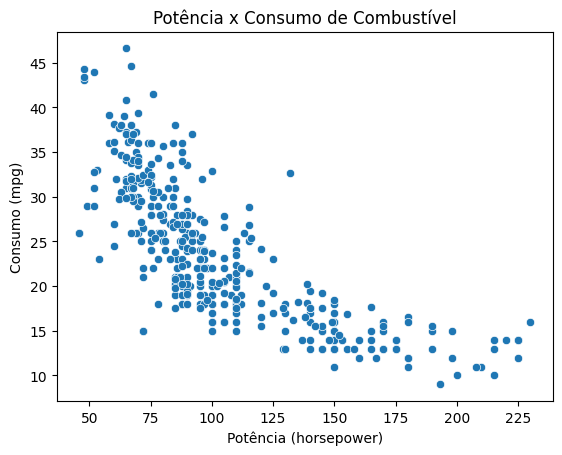

In [12]:
mpg = sns.load_dataset('mpg')

sns.scatterplot(data=mpg, x='horsepower', y='mpg')

plt.title('Potência x Consumo de Combustível')
plt.xlabel('Potência (horsepower)')
plt.ylabel('Consumo (mpg)')
plt.show()

- 5. Utilizando o dataset paises.csv, calcule a correlação entre
“GDP ($ percapita)”, “Literacy (%)”, “Infant mortality (per 1000 births)” e
“Phones (per
1000)”, apresentando o resultado em um Heatmap com os valores numéricos
exibidos;

- 6. Com o dataset paises.csv, trace um Boxplot comparando a distribuição do “GDP ($ per capita)” entre os países da América Latina e da Europa
Ocidental, permitindo assim identificar mediana, dispersão e outliers de
cada grupo;

- 7. Utilizando o dataset paises.csv, trace um Regplot relacionando a taxa de
alfabetização
(Literacy (%)) com a mortalidade infantil
(Infant mortality (per
1000 births)), customizando a cor da linha de regressão;

- 8. Por meio do dataset space.csv, após filtrar apenas as missões com custo
conhecido (Cost > 0), trace um Boxplot comparando a distribuição do custo
das missões
(Cost) entre foguetes com status
“StatusActive” e
“StatusRetired”, permitindo identificar mediana, dispersão e outliers de
cada grupo. negrito

                                    GDP ($ per capita)  Literacy (%)  \
GDP ($ per capita)                            1.000000      0.311009   
Literacy (%)                                  0.311009      1.000000   
Infant mortality (per 1000 births)           -0.585866     -0.355678   
Phones (per 1000)                             0.828151      0.239245   

                                    Infant mortality (per 1000 births)  \
GDP ($ per capita)                                           -0.585866   
Literacy (%)                                                 -0.355678   
Infant mortality (per 1000 births)                            1.000000   
Phones (per 1000)                                            -0.647702   

                                    Phones (per 1000)  
GDP ($ per capita)                           0.828151  
Literacy (%)                                 0.239245  
Infant mortality (per 1000 births)          -0.647702  
Phones (per 1000)                           

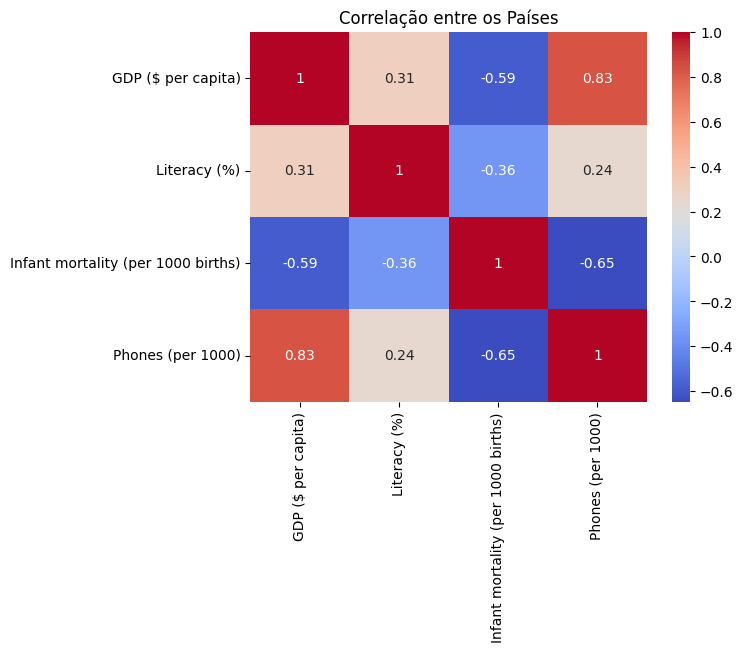

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

d_paises = pd.read_csv('paises.csv', delimiter=';')

colunas = ['GDP ($ per capita)', 'Literacy (%)', 'Infant mortality (per 1000 births)', 'Phones (per 1000)']

correlacao = d_paises[colunas].corr()

print(correlacao)

sns.heatmap(correlacao, annot=True, cmap='coolwarm')
plt.title('Correlação entre os Países')
plt.show()

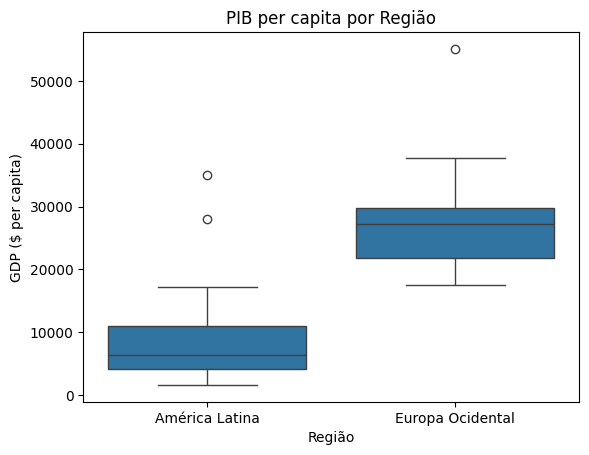

In [24]:
america_latina = d_paises.loc[d_paises['Region'].str.contains('LATIN AMER. & CARIB', na=False)]
europa_ocidental = d_paises.loc[d_paises['Region'].str.contains('WESTERN EUROPE', na=False)]

dados = pd.concat([
    america_latina.assign(Grupo='América Latina'),
    europa_ocidental.assign(Grupo='Europa Ocidental')
])

sns.boxplot(data=dados, x='Grupo', y='GDP ($ per capita)')
plt.title('PIB per capita por Região')
plt.xlabel('Região')
plt.ylabel('GDP ($ per capita)')
plt.show()

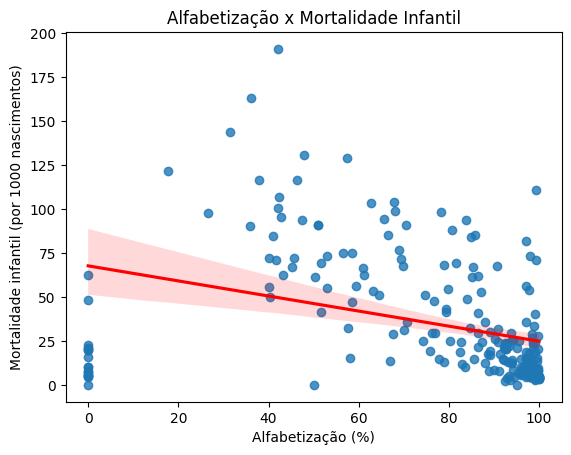

In [25]:
sns.regplot(data=d_paises, x='Literacy (%)',y='Infant mortality (per 1000 births)',line_kws={'color': 'red'})

plt.title('Alfabetização x Mortalidade Infantil')
plt.xlabel('Alfabetização (%)')
plt.ylabel('Mortalidade infantil (por 1000 nascimentos)')
plt.show()

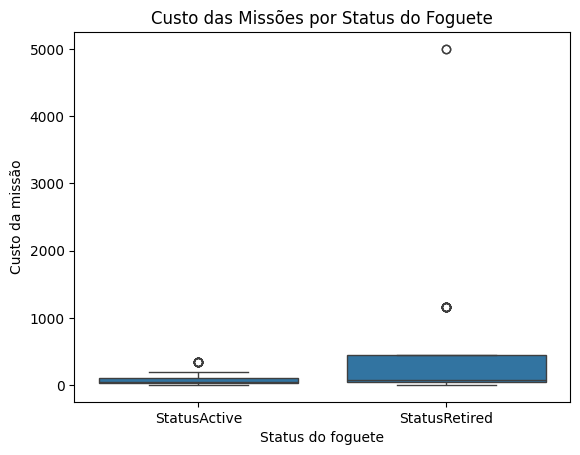

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

d_space = pd.read_csv('space.csv', delimiter=';')

d_space.columns = d_space.columns.str.strip()

#pedi ajuda do chat pois n estava conseguindo usar o cost
d_space['Cost'] = d_space['Cost'].astype(str).str.replace(',', '').str.strip()
d_space['Cost'] = pd.to_numeric(d_space['Cost'], errors='coerce')

space_custo = d_space.loc[
    (d_space['Cost'] > 0) &
    (d_space['Status Rocket'].isin(['StatusActive', 'StatusRetired']))]

sns.boxplot(data=space_custo, x='Status Rocket', y='Cost')
plt.title('Custo das Missões por Status do Foguete')
plt.xlabel('Status do foguete')
plt.ylabel('Custo da missão')
plt.show()